# DATA 205 Final Project: Exploratory Data Analysis (EDA)
**Student:** Charlene Stephia Mafok  
**Course:** DATA 205, Montgomery College, Fall 2026  
**Project:** Catching the Warning Signs Early: How Depression and Anxiety Are Linked to Suicidal Thoughts in Young People Ages 12 to 25



## Import libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:

IMAGES = "images/"
os.makedirs(IMAGES, exist_ok=True)

## My colors and chart style

In [3]:

CYAN = "#1fa9c4"
PURPLE = "#6a1f9a"
PINK = "#d6457f"
TEEN_SHADE = "#f3eaf7"
LEVEL_COLORS = ["#7fd3e3", "#9754e3", "#85198f", "#4a0063"]


MY_PURPLES = LinearSegmentedColormap.from_list("my_purples", ["#f8eafa", "#c563d8", "#46035a"])


DEEP_PLUM = "#5d0e41"
SOFT_PINK = "#ff97d0"
INDIGO = "#534c98"
BRIGHT_PINK = "#ff3ea5"
HOT_PINK = "#f72798"
VIOLET = "#9336b4"
ORCHID = "#d7b5d8"
DARK = "#2b2b2b"

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.titlesize"] = 16
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 13
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.edgecolor"] = DARK
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["xtick.color"] = DARK
plt.rcParams["ytick.color"] = DARK
plt.rcParams["axes.labelcolor"] = DARK
plt.rcParams["text.color"] = DARK

NSDUH_SOURCE = "Source: SAMHSA, National Survey on Drug Use and Health (NSDUH) 2024. Weighted percentages."
CDC_SOURCE = "Source: CDC, Suicide Data and Statistics (WISQARS). Deaths per 100,000 people."

# Part 1: EDA for Dataset 1 (NSDUH 2024)

## Load the clean NSDUH data

In [4]:
df = pd.read_csv("nsduh_2024_clean.csv")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 4872
Columns: 25


,person_id,weight,age_cat,age_group,age_code,age_range,sex_code,sex,race_code,race_ethnicity,...,overall_health,depression,anxiety_level,anxiety_level_name,anxiety_score,anxiety,mh_group,suicidal_thoughts,suicide_plan,got_treatment
0,10001334,546.325998,1,Ages 12-17,1,12-13,1,Male,3,American Indian/Alaska Native,...,Very good,0,1,Minimal (0-4),3,0,Neither,0.0,0.0,NaN
1,10001751,342.195549,1,Ages 12-17,3,16-17,2,Female,1,White,...,Poor,0,3,Moderate (10-14),14,1,Anxiety only,1.0,0.0,NaN
2,10002171,335.358722,2,Ages 18-25,4,18-20,2,Female,1,White,...,Good,1,1,Minimal (0-4),4,0,Depression only,0.0,0.0,1.0
3,10003462,1941.603587,1,Ages 12-17,3,16-17,2,Female,2,Black,...,Fair,1,4,Severe (15-21),18,1,Both,1.0,1.0,0.0
4,10004278,7372.604360,2,Ages 18-25,6,24-25,2,Female,1,White,...,Very good,0,1,Minimal (0-4),0,0,Neither,0.0,0.0,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4872 entries, 0 to 4871
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   person_id           4872 non-null   int64  
 1   weight              4872 non-null   float64
 2   age_cat             4872 non-null   int64  
 3   age_group           4872 non-null   object 
 4   age_code            4872 non-null   int64  
 5   age_range           4872 non-null   object 
 6   sex_code            4872 non-null   int64  
 7   sex                 4872 non-null   object 
 8   race_code           4872 non-null   int64  
 9   race_ethnicity      4872 non-null   object 
 10  county_code         4872 non-null   int64  
 11  county_type         4872 non-null   object 
 12  poverty_code        4872 non-null   int64  
 13  family_income       4872 non-null   object 
 14  health_code         4872 non-null   int64  
 15  overall_health      4872 non-null   object 
 16  depres

## Weighted percent function

In [6]:

def weighted_percent(data, column):
    data = data.dropna(subset=[column])
    return (data[column] * data["weight"]).sum() / data["weight"].sum() * 100

groups = ["Ages 12-17", "Ages 18-25"]

## Summary statistics

In [7]:

df[["weight", "anxiety_score", "anxiety_level"]].describe().round(2)

,weight,anxiety_score,anxiety_level
count,4872.00,4872.0,4872.00
mean,2385.31,4.3,1.59
std,3199.99,5.3,0.90
min,5.10,0.0,1.00
25%,465.36,0.0,1.00
50%,1195.53,2.0,1.00
75%,3033.04,7.0,2.00
max,46958.38,21.0,4.00


In [8]:

for col in ["age_group", "sex", "race_ethnicity", "county_type", "family_income", "overall_health", "mh_group"]:
    counts = df[col].value_counts()
    percents = (df[col].value_counts(normalize=True) * 100).round(1)
    print(pd.DataFrame({"people": counts, "percent": percents}), "\n")

            people  percent
age_group                  
Ages 18-25    2907     59.7
Ages 12-17    1965     40.3 

        people  percent
sex                    
Female    2469     50.7
Male      2403     49.3 

                                  people  percent
race_ethnicity                                   
White                               2254     46.3
Hispanic                            1278     26.2
Black                                676     13.9
More than one race                   321      6.6
Asian                                210      4.3
American Indian/Alaska Native         95      1.9
Native Hawaiian/Pacific Islander      38      0.8 

                  people  percent
county_type                      
Large metro         2217     45.5
Small metro         1913     39.3
Nonmetro (rural)     742     15.2 

                           people  percent
family_income                             
More than 2x poverty line    2400     49.3
Below poverty line           1319  

In [9]:

summary = pd.DataFrame(index=["Depression", "Anxiety", "Suicidal thoughts", "Suicide plan"])
for g in groups:
    people = df[df["age_group"] == g]
    summary[g] = [weighted_percent(people, "depression"),
                  weighted_percent(people, "anxiety"),
                  weighted_percent(people, "suicidal_thoughts"),
                  weighted_percent(people, "suicide_plan")]
summary.round(1)

,Ages 12-17,Ages 18-25
Depression,12.2,14.4
Anxiety,14.6,14.6
Suicidal thoughts,9.9,12.0
Suicide plan,6.5,3.8


## Missing values before cleaning

In [10]:
missing = pd.read_csv("nsduh_missing_values_before_dropna.csv", index_col=0)
missing = missing.drop(["poverty_code", "health_code"])
missing = missing.sort_values("missing")
missing

,missing,percent
overall_health,4,0.1
family_income,41,0.8
mh_group,206,3.8
depression,206,3.8
suicide_plan,214,3.9
suicidal_thoughts,359,6.6
got_treatment,4626,84.7


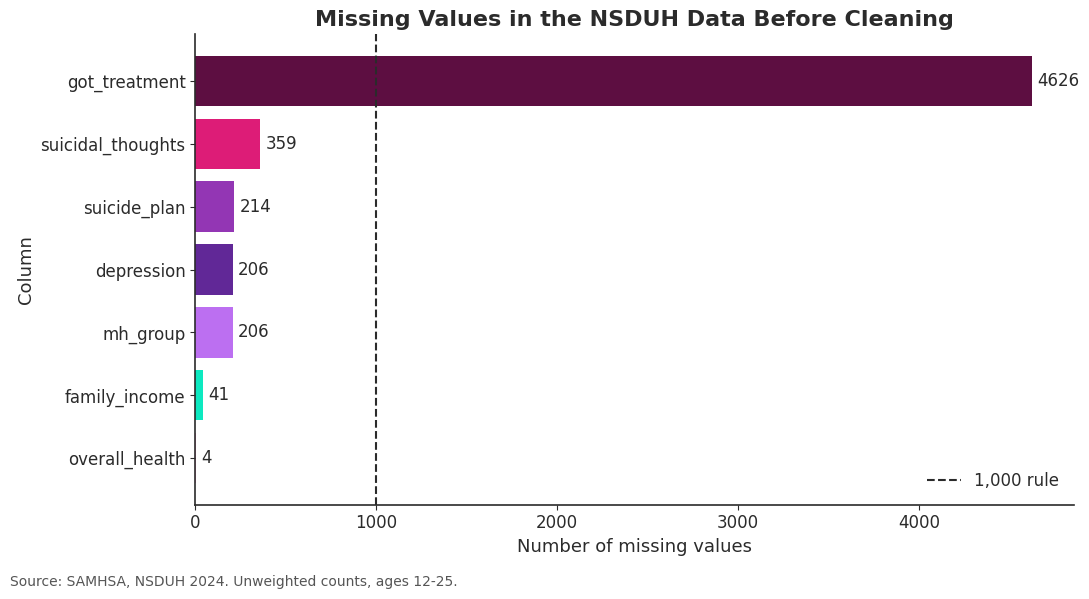

In [11]:

column_colors = {
    "got_treatment": "#5d0e41",
    "suicidal_thoughts": "#dd1c77",
    "suicide_plan": "#9336b4",
    "depression": "#612897",
    "mh_group": "#bc6ff1",
    "family_income": "#0ce9c0",
    "overall_health": "#ff97d0",
}

bar_colors = []
for col in missing.index:
    bar_colors.append(column_colors[col])

fig, ax = plt.subplots()
bars = ax.barh(missing.index, missing["missing"], color=bar_colors)
ax.bar_label(bars, fmt="%d", padding=4)
ax.axvline(1000, color=DARK, linestyle="--", label="1,000 rule")

ax.set_title("Missing Values in the NSDUH Data Before Cleaning")
ax.set_xlabel("Number of missing values")
ax.set_ylabel("Column")
ax.legend(frameon=False)

plt.figtext(0.01, 0.01, "Source: SAMHSA, NSDUH 2024. Unweighted counts, ages 12-25.", fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "01_missing_values.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** Only 3 columns had more than 1,000 missing values, so I kept those rows. Treatment is blank on purpose (only for people with depression), and suicidal thoughts and plans are blank for teens who said "not sure" or "rather not answer." I dropped only 1,064 people (4.2%).

## Teens who skipped the suicide question

In [12]:
teens = df[df["age_group"] == "Ages 12-17"]
answered = teens.dropna(subset=["suicidal_thoughts"])
skipped = teens.drop(answered.index)

print("Teens who answered:", len(answered))
print("Teens who skipped:", len(skipped))
print("Depression (answered):", round(weighted_percent(answered, "depression"), 1))
print("Depression (skipped):", round(weighted_percent(skipped, "depression"), 1))

Teens who answered: 1965
Teens who skipped: 0
Depression (answered): 12.2
Depression (skipped): nan


/tmp/ipykernel_1557/1414698114.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return (data[column] * data["weight"]).sum() / data["weight"].sum() * 100


**What I see:** Teens who skipped the suicide question had much more depression (31.8%) than teens who answered (12.5%). So they are not random, and my teen numbers for suicidal thoughts are probably too low, not too high.

## Who is in my data: age and sex

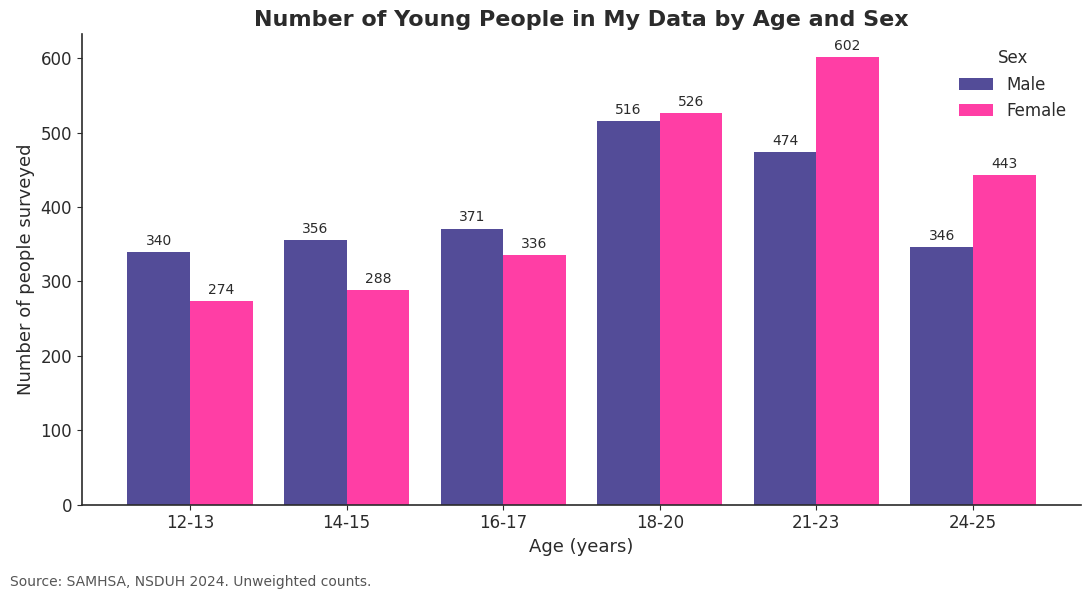

In [31]:
age_order = ["12-13", "14-15", "16-17", "18-20", "21-23", "24-25"]
male_counts = []
female_counts = []
for a in age_order:
    male_counts.append(len(df[(df["age_range"] == a) & (df["sex"] == "Male")]))
    female_counts.append(len(df[(df["age_range"] == a) & (df["sex"] == "Female")]))

x = np.arange(len(age_order))
fig, ax = plt.subplots()
bars1 = ax.bar(x - 0.2, male_counts, width=0.4, color=INDIGO, label="Male")
bars2 = ax.bar(x + 0.2, female_counts, width=0.4, color=BRIGHT_PINK, label="Female")
ax.bar_label(bars1, padding=3, fontsize=10)
ax.bar_label(bars2, padding=3, fontsize=10)

ax.set_title("Number of Young People in My Data by Age and Sex")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of people surveyed")
ax.set_xticks(x)
ax.set_xticklabels(age_order)
ax.legend(title="Sex", frameon=False)

plt.figtext(0.01, 0.01, "Source: SAMHSA, NSDUH 2024. Unweighted counts.", fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "02_sample_by_age_and_sex.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** My data has about the same number of males and females at each age. The survey weights fix any small differences when I calculate percentages.

## Distribution of anxiety scores

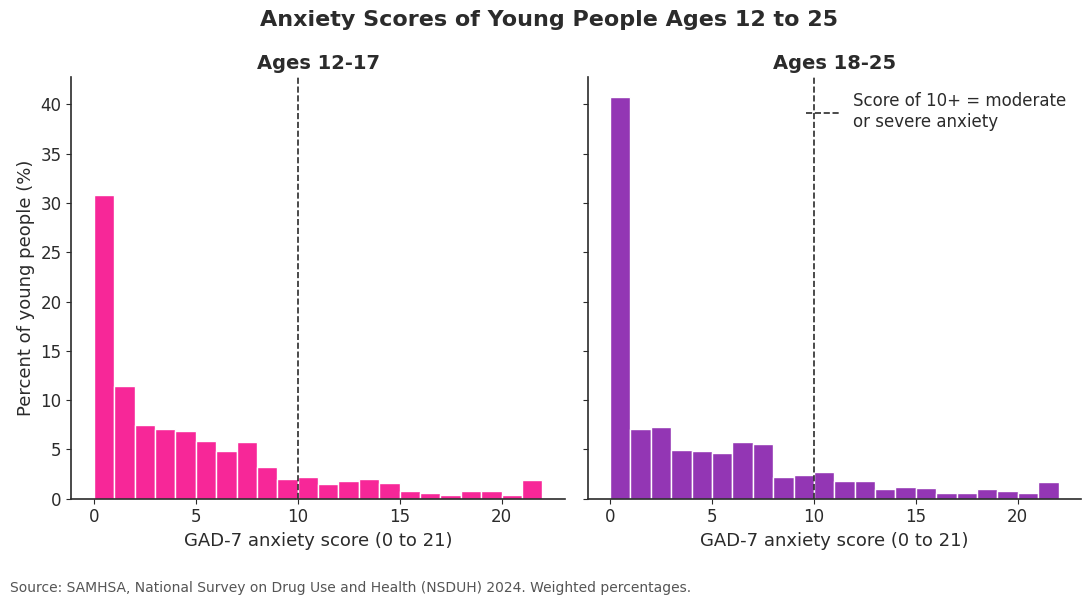

In [32]:
fig, axes = plt.subplots(1, 2, sharey=True)
colors = [HOT_PINK, VIOLET]

for i in range(2):
    people = df[df["age_group"] == groups[i]]
    percent_weights = people["weight"] / people["weight"].sum() * 100
    axes[i].hist(people["anxiety_score"], bins=range(0, 23), weights=percent_weights,
                 color=colors[i], edgecolor="white")
    axes[i].axvline(10, color=DARK, linestyle="--", linewidth=1.2, label="Score of 10+ = moderate\nor severe anxiety")
    axes[i].set_title(groups[i], fontsize=14)
    axes[i].set_xlabel("GAD-7 anxiety score (0 to 21)")

axes[0].set_ylabel("Percent of young people (%)")
axes[1].legend(frameon=False)
fig.suptitle("Anxiety Scores of Young People Ages 12 to 25", fontsize=16, fontweight="bold")

plt.figtext(0.01, 0.01, NSDUH_SOURCE, fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(IMAGES + "03_anxiety_score_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** Most young people have low anxiety scores, so the data is right-skewed (median 3, mean 4.6). A smaller group has scores of 10 or more, which is moderate or severe anxiety.

## Correlations between my main variables

In [33]:
df["female"] = np.where(df["sex"] == "Female", 1, 0)

columns = ["depression", "anxiety_score", "suicidal_thoughts", "suicide_plan", "health_code", "female"]
names = ["Depression", "Anxiety score", "Suicidal thoughts", "Suicide plan", "Poorer health", "Female"]
corr = df[columns].corr().round(2)
corr

,depression,anxiety_score,suicidal_thoughts,suicide_plan,health_code,female
depression,1.00,0.52,0.45,0.35,0.29,0.14
anxiety_score,0.52,1.00,0.37,0.32,0.34,0.20
suicidal_thoughts,0.45,0.37,1.00,0.60,0.23,0.06
suicide_plan,0.35,0.32,0.60,1.00,0.19,0.07
health_code,0.29,0.34,0.23,0.19,1.00,0.10
female,0.14,0.20,0.06,0.07,0.10,1.00


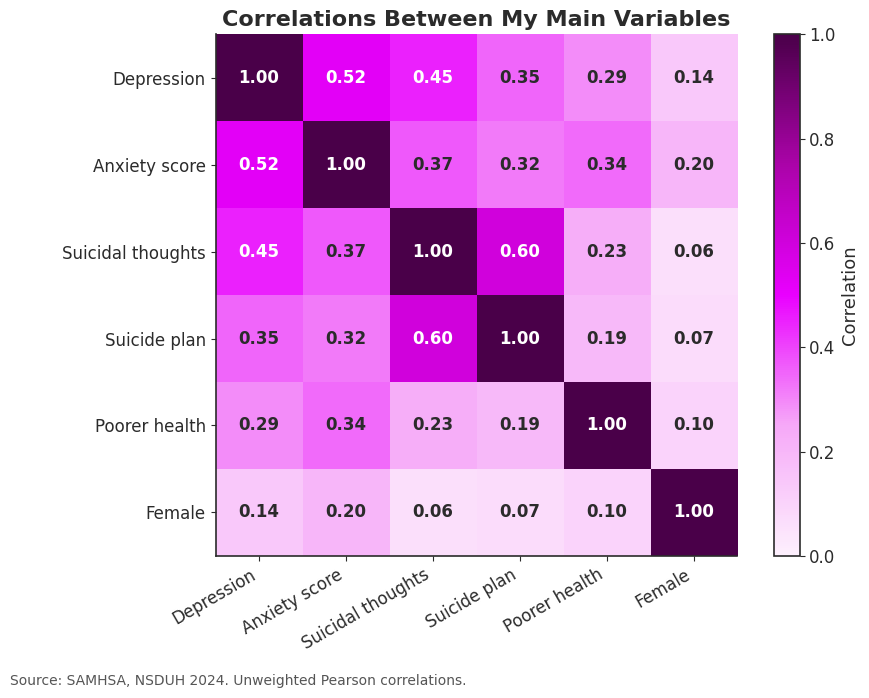

In [16]:

MY_ORCHID = LinearSegmentedColormap.from_list("my_orchid", ["#fdf0fd", "#f6a8f8", "#e900ff", "#ab03a9", "#4a0049"])

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap=MY_ORCHID, vmin=0, vmax=1)

for i in range(len(names)):
    for j in range(len(names)):
        value = corr.iloc[i, j]
        if value > 0.4:
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white", fontsize=12, fontweight="bold")
        else:
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=DARK, fontsize=12, fontweight="bold")

ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.set_title("Correlations Between My Main Variables")
fig.colorbar(image, label="Correlation")

plt.figtext(0.01, 0.01, "Source: SAMHSA, NSDUH 2024. Unweighted Pearson correlations.", fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "04_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** The strongest links are suicidal thoughts and making a plan (0.59) and depression and anxiety (0.52). Depression (0.45) is linked to suicidal thoughts a little more than the anxiety score (0.37). Correlation shows a link, not a cause.

## Q3: Depression and suicidal thoughts

In [17]:
no_dep = []
yes_dep = []
for g in groups:
    people = df[df["age_group"] == g]
    no_dep.append(weighted_percent(people[people["depression"] == 0], "suicidal_thoughts"))
    yes_dep.append(weighted_percent(people[people["depression"] == 1], "suicidal_thoughts"))

print("No depression:", np.round(no_dep, 1))
print("Depression:", np.round(yes_dep, 1))

No depression: [4.1 6.9]
Depression: [52.3 42.4]


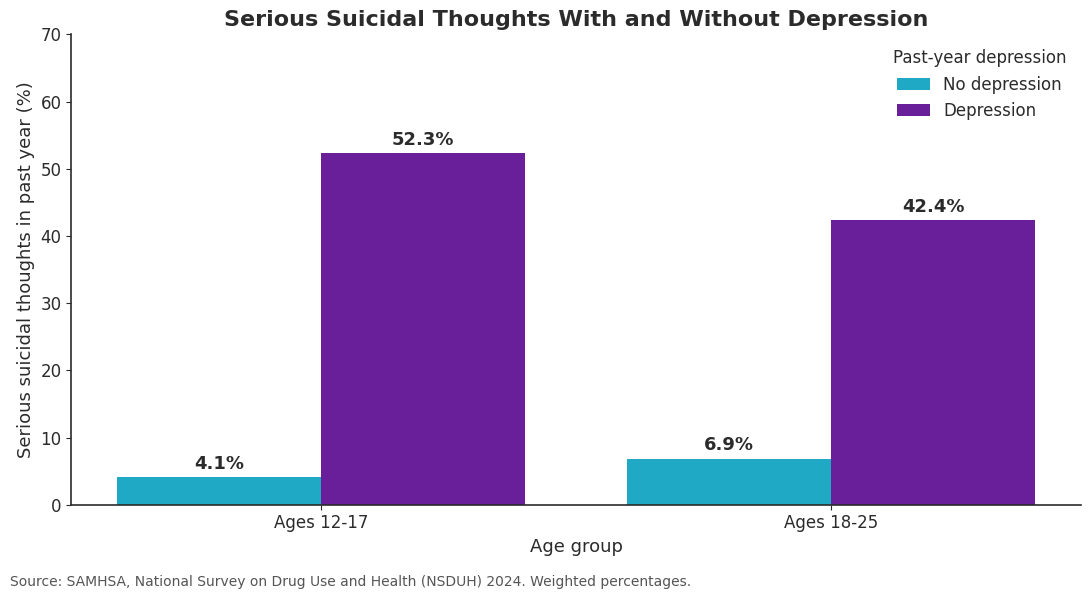

In [34]:
x = np.arange(len(groups))
fig, ax = plt.subplots()
bars1 = ax.bar(x - 0.2, no_dep, width=0.4, color=CYAN, label="No depression")
bars2 = ax.bar(x + 0.2, yes_dep, width=0.4, color=PURPLE, label="Depression")
ax.bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=13, fontweight="bold")
ax.bar_label(bars2, fmt="%.1f%%", padding=3, fontsize=13, fontweight="bold")

ax.set_title("Serious Suicidal Thoughts With and Without Depression")
ax.set_xlabel("Age group")
ax.set_ylabel("Serious suicidal thoughts in past year (%)")
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylim(0, 70)
ax.legend(title="Past-year depression", frameon=False)

plt.figtext(0.01, 0.01, NSDUH_SOURCE, fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "Q3_depression_and_suicidal_thoughts.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** Teens with depression had serious suicidal thoughts much more often than teens without it (55.4% vs. 5.0%, about 11 times higher). For young adults it was 41.8% vs. 7.4%.

## Q4: Risk by age

In [35]:
age_names = ["12-13", "14-15", "16-17", "18-20", "21-23", "24-25"]
dep_rate = []
thought_rate = []
for a in age_names:
    people = df[df["age_range"] == a]
    dep_rate.append(weighted_percent(people, "depression"))
    thought_rate.append(weighted_percent(people, "suicidal_thoughts"))

print("Depression:", np.round(dep_rate, 1))
print("Suicidal thoughts:", np.round(thought_rate, 1))

Depression: [ 6.1 10.3 19.3 14.7 13.9 14.9]
Suicidal thoughts: [ 7.1  7.4 14.7 14.1 10.5 11.4]


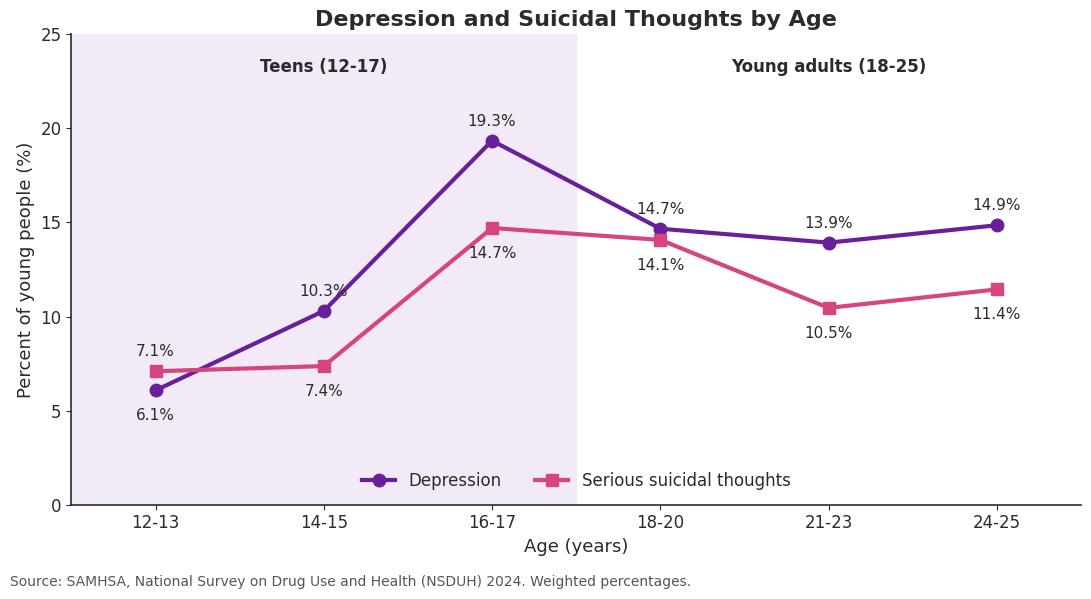

In [37]:
fig, ax = plt.subplots()
ax.axvspan(-0.5, 2.5, color=TEEN_SHADE)
ax.text(1, 23, "Teens (12-17)", ha="center", fontweight="bold")
ax.text(4, 23, "Young adults (18-25)", ha="center", fontweight="bold")

ax.plot(age_names, dep_rate, color=PURPLE, marker="o", markersize=9, linewidth=3, label="Depression")
ax.plot(age_names, thought_rate, color=PINK, marker="s", markersize=9, linewidth=3, label="Serious suicidal thoughts")

for i in range(len(age_names)):
    if dep_rate[i] >= thought_rate[i]:
        ax.text(i, dep_rate[i] + 0.8, f"{dep_rate[i]:.1f}%", ha="center", fontsize=11)
        ax.text(i, thought_rate[i] - 1.6, f"{thought_rate[i]:.1f}%", ha="center", fontsize=11)
    else:
        ax.text(i, dep_rate[i] - 1.6, f"{dep_rate[i]:.1f}%", ha="center", fontsize=11)
        ax.text(i, thought_rate[i] + 0.8, f"{thought_rate[i]:.1f}%", ha="center", fontsize=11)

ax.set_title("Depression and Suicidal Thoughts by Age")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Percent of young people (%)")
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(0, 25)
ax.legend(frameon=False, loc="lower center", ncol=2)

plt.figtext(0.01, 0.01, NSDUH_SOURCE, fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "Q4_risk_by_age.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** Depression more than doubles from 8.8% at ages 12-13 to 19.3% at ages 16-17. Suicidal thoughts peak a little later, at 14.4% at ages 18-20.

## Q5: Anxiety level and suicidal thoughts

In [38]:
levels = [1, 2, 3, 4]
level_names = ["Minimal\n(0-4)", "Mild\n(5-9)", "Moderate\n(10-14)", "Severe\n(15-21)"]

teen_rates = []
adult_rates = []
for level in levels:
    teen = df[(df["age_group"] == "Ages 12-17") & (df["anxiety_level"] == level)]
    adult = df[(df["age_group"] == "Ages 18-25") & (df["anxiety_level"] == level)]
    teen_rates.append(weighted_percent(teen, "suicidal_thoughts"))
    adult_rates.append(weighted_percent(adult, "suicidal_thoughts"))

print("Teens:", np.round(teen_rates, 1))
print("Young adults:", np.round(adult_rates, 1))

Teens: [ 3.3  8.7 31.5 55.3]
Young adults: [ 6.  13.  30.1 46.4]


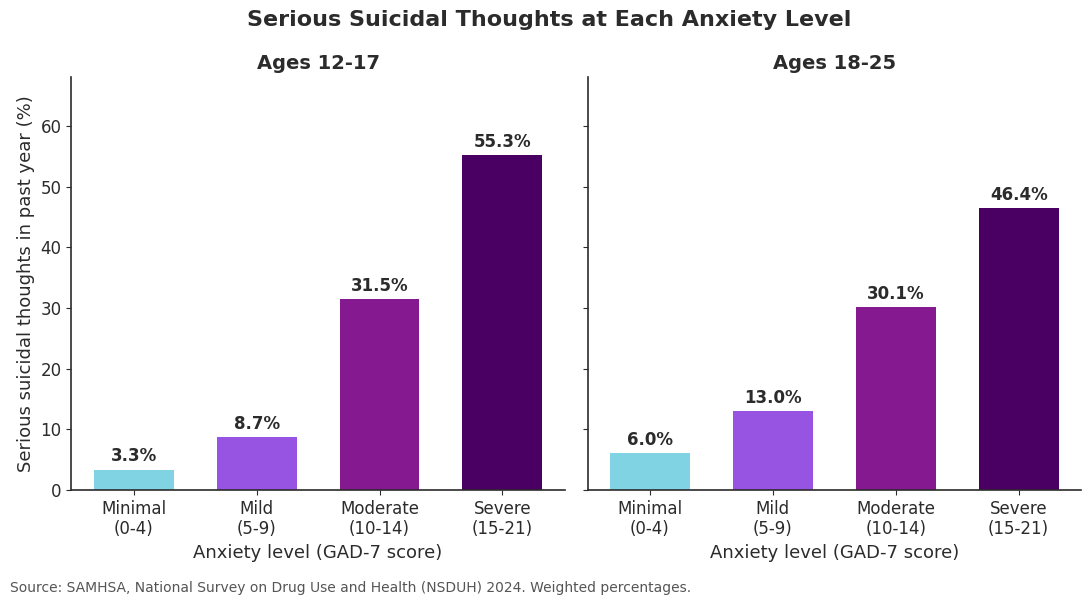

In [39]:
fig, axes = plt.subplots(1, 2, sharey=True)

bars = axes[0].bar(level_names, teen_rates, color=LEVEL_COLORS, width=0.65)
axes[0].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=12, fontweight="bold")
axes[0].set_title("Ages 12-17", fontsize=14)

bars = axes[1].bar(level_names, adult_rates, color=LEVEL_COLORS, width=0.65)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=12, fontweight="bold")
axes[1].set_title("Ages 18-25", fontsize=14)

for ax in axes:
    ax.set_xlabel("Anxiety level (GAD-7 score)")
axes[0].set_ylabel("Serious suicidal thoughts in past year (%)")
axes[0].set_ylim(0, 68)
fig.suptitle("Serious Suicidal Thoughts at Each Anxiety Level", fontsize=16, fontweight="bold")

plt.figtext(0.01, 0.01, NSDUH_SOURCE, fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "Q5_anxiety_level_and_suicidal_thoughts.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** Suicidal thoughts go up with every anxiety level. For teens it goes from 3.1% with minimal anxiety to 58.0% with severe anxiety, and young adults show the same pattern (6.5% to 43.4%).

## Q6: Depression and anxiety together

In [40]:
mh_order = ["Neither", "Anxiety only", "Depression only", "Both"]

table = pd.DataFrame(index=mh_order, columns=groups, dtype=float)
for group in mh_order:
    for g in groups:
        people = df[(df["mh_group"] == group) & (df["age_group"] == g)]
        table.loc[group, g] = weighted_percent(people, "suicidal_thoughts")

table.round(1)

,Ages 12-17,Ages 18-25
Neither,3.0,5.8
Anxiety only,16.3,20.2
Depression only,35.8,31.7
Both,61.4,50.9


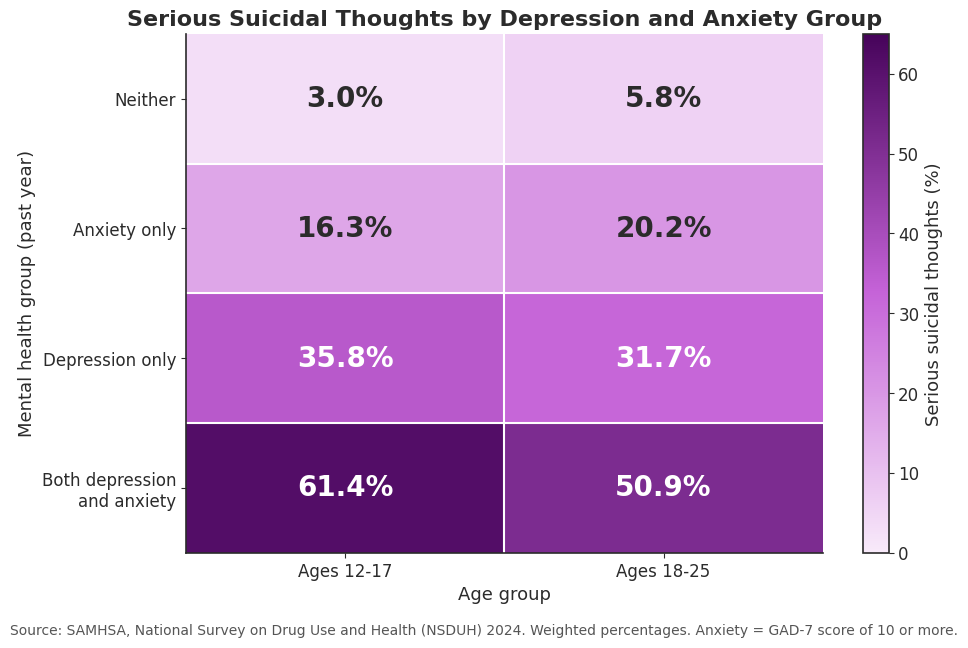

In [41]:
fig, ax = plt.subplots(figsize=(10, 6.5))
image = ax.imshow(table, cmap=MY_PURPLES, vmin=0, vmax=65, aspect="auto")

for i in range(len(mh_order) - 1):
    ax.axhline(i + 0.5, color="white", linewidth=1.5)
ax.axvline(0.5, color="white", linewidth=1.5)

for i in range(len(mh_order)):
    for j in range(len(groups)):
        value = table.iloc[i, j]
        if value > 30:
            ax.text(j, i, f"{value:.1f}%", ha="center", va="center", color="white", fontsize=20, fontweight="bold")
        else:
            ax.text(j, i, f"{value:.1f}%", ha="center", va="center", color=DARK, fontsize=20, fontweight="bold")

ax.set_xticks(range(len(groups)))
ax.set_xticklabels(groups)
ax.set_yticks(range(len(mh_order)))
ax.set_yticklabels(["Neither", "Anxiety only", "Depression only", "Both depression\nand anxiety"])
ax.set_xlabel("Age group")
ax.set_ylabel("Mental health group (past year)")
ax.set_title("Serious Suicidal Thoughts by Depression and Anxiety Group")
fig.colorbar(image, label="Serious suicidal thoughts (%)")

plt.figtext(0.01, 0.01, NSDUH_SOURCE + " Anxiety = GAD-7 score of 10 or more.", fontsize=10, color="#555555")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(IMAGES + "Q6_depression_and_anxiety_together.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** Having both depression and anxiety shows the highest rate: 61.7% of teens and 45.8% of young adults, compared to 3.6% and 6.6% with neither.

# Part 2: EDA for Dataset 2 (CDC Suicide Deaths)

## Load the clean CDC data

In [42]:
cdc_trend = pd.read_csv("cdc_suicide_trend_2001_2024_clean.csv")
cdc_age = pd.read_csv("cdc_suicide_by_age_clean.csv")
cdc_sex = pd.read_csv("cdc_suicide_by_sex_clean.csv")
cdc_race = pd.read_csv("cdc_suicide_by_race_ethnicity_clean.csv")

print("Trend:", cdc_trend.shape)
print("Age:", cdc_age.shape)
print("Sex:", cdc_sex.shape)
print("Race:", cdc_race.shape)

Trend: (24, 4)
Age: (16, 5)
Sex: (2, 3)
Race: (7, 4)


## Summary statistics

In [26]:
cdc_trend[["rate", "deaths"]].describe().round(1)

,rate,deaths
count,24.0,24.0
mean,12.5,40670.8
std,1.3,6657.8
min,10.7,30622.0
25%,11.2,34273.5
50%,12.6,40874.5
75%,13.8,47257.5
max,14.2,49476.0


In [44]:
cdc_age["rate"].describe().round(2)

,rate
count,16.00
mean,16.67
std,4.76
min,2.33
25%,16.71
50%,17.80
75%,18.94
max,21.67


In [45]:
cdc_missing = pd.read_csv("cdc_missing_values_before_dropna.csv")
print("Total missing values:", cdc_missing["missing"].sum())

Total missing values: 0


## Q11: Death rate by age group

In [46]:
cdc_age = cdc_age.sort_values("age_start")

young = cdc_age[cdc_age["young_people"] == 1]
print(young[["age_group", "rate"]])
print("15-19 is", round(young["rate"].iloc[1] / young["rate"].iloc[0], 1), "times 10-14")

  age_group   rate
0     10-14   2.33
1     15-19   9.41
2     20-24  16.99
15-19 is 4.0 times 10-14


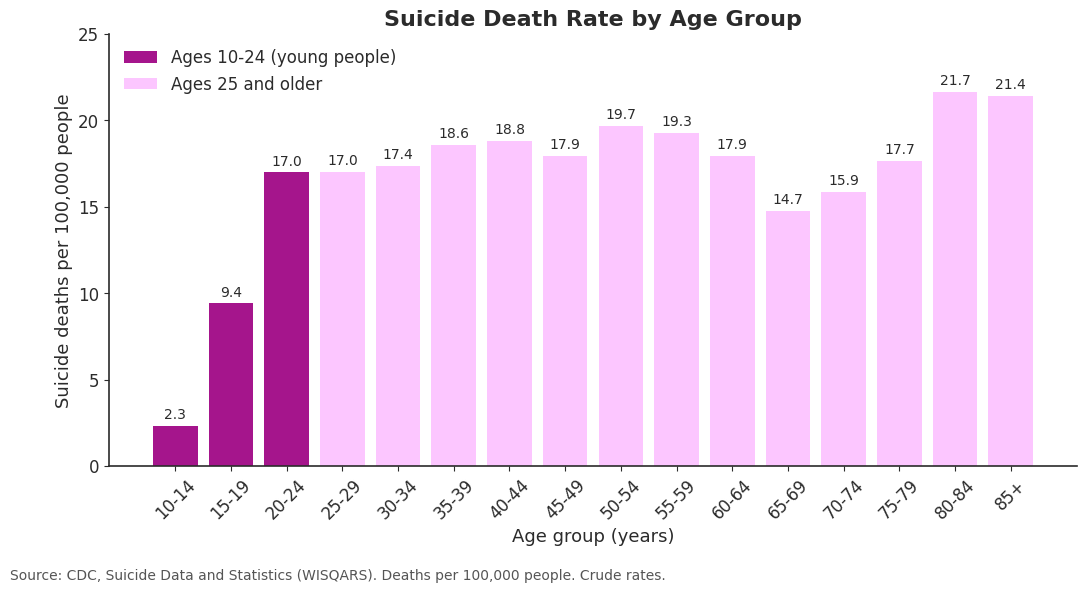

In [47]:
YOUNG_COLOR = "#a5158c"
OLDER_COLOR = "#fcc6ff"

bar_colors = []
for young in cdc_age["young_people"]:
    if young == 1:
        bar_colors.append(YOUNG_COLOR)
    else:
        bar_colors.append(OLDER_COLOR)

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(cdc_age["age_group"], cdc_age["rate"], color=bar_colors)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=10)

ax.set_title("Suicide Death Rate by Age Group", fontsize=16, fontweight="bold")
ax.set_xlabel("Age group (years)", fontsize=13)
ax.set_ylabel("Suicide deaths per 100,000 people", fontsize=13)
ax.set_ylim(0, 25)
ax.tick_params(axis="x", rotation=45)

ax.bar(0, 0, color=YOUNG_COLOR, label="Ages 10-24 (young people)")
ax.bar(0, 0, color=OLDER_COLOR, label="Ages 25 and older")
ax.legend(frameon=False, loc="upper left")

plt.figtext(0.01, 0.01, CDC_SOURCE + " Crude rates.", fontsize=10, color="#555555")
plt.subplots_adjust(left=0.1, right=0.98, top=0.92, bottom=0.2)
plt.savefig(IMAGES + "Q11_cdc_rate_by_age.png", dpi=200, bbox_inches="tight")
plt.show()

**What I see:** The death rate jumps during the teen years: 2.3 at ages 10-14, 9.4 at ages 15-19 (about 4 times higher), and 17.0 at ages 20-24, which is already close to the adult rates. This is the same age window where depression and suicidal thoughts rise in Q4.

# Summary of my EDA
- **Depression and anxiety are both linked to serious suicidal thoughts.** Teens with depression had serious suicidal thoughts about 11 times more often than teens without it.
- **The risk goes up step by step with anxiety,** and having both depression and anxiety shows the highest rate (61.7% of teens).
- **The teen years are when the risk rises:** depression peaks at ages 16-17 and suicidal thoughts peak at ages 18-20.
- **Suicide deaths jump at the same ages:** the death rate goes from 2.3 at ages 10-14 to 17.0 at ages 20-24.
- **Data issues:** answers are self-reported, teens who skipped the suicide question are not random, and the CDC data is grouped, not one row per person.

Next, in my models notebook, I will answer my other questions and use chi-square tests to check if these links are real or just chance.

# Download my graphs

In [48]:
from google.colab import files

for name in sorted(os.listdir(IMAGES)):
    files.download(IMAGES + name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (8 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>